In [1]:
import sys, matplotlib.pyplot as plt
import os
import pandas as pd
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

# monocular (eye-conditioned)
from src.data.DisparityDevice import DisparityDevice
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SessionVisualizer
from src.analysis.CellAnalysis import SessionAnalyzer
# disparity (disparity-conditioned)
from src.data.DisparityStimDevice import DisparityStimDevice
from src.viz.DisparityCellVisualizer import DisparityCellVisualizer
from src.viz.DisparitySessionVisualizer import DisparitySessionVisualizer
from src.analysis.DisparityAnalysis import DisparitySessionAnalyzer

%load_ext autoreload
%autoreload 2

KeyboardInterrupt: 

Directory results already exists
eyes: ['right', 'left']
Loaded cached stats: D:/data-distance-coding-project/processed-data\260616_SAM045_goggles\260616_SAM045_goggles_dataframe.pkl
 Session: 260616_SAM045_goggles
 Eyes shown: right, left
 Total cells: 881
--------------------------------------------------
 Right reliable        :  277  ( 31.4%)
 Left reliable         :   48  (  5.4%)
 Both eyes reliable    :   25  (  2.8%)
--------------------------------------------------
 Right-only            :  252
 Left-only             :   23
 Either eye            :  300  ( 34.1%)
 Neither               :  581  ( 65.9%)
 Session: 260616_SAM045_goggles
 Eyes shown: right, left
 Total cells: 881
--------------------------------------------------
 Right reliable        :  277  ( 31.4%)
 Left reliable         :   48  (  5.4%)
 Both eyes reliable    :   25  (  2.8%)
--------------------------------------------------
 Right-only            :  252
 Left-only             :   23
 Either eye            

KeyError: 'start_deg'

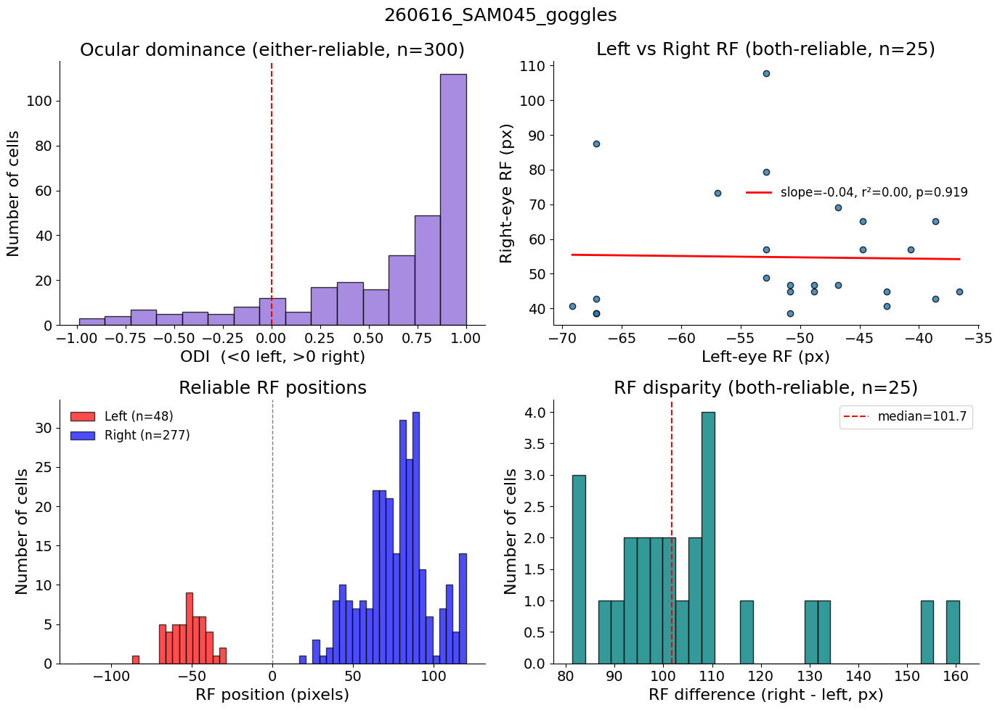

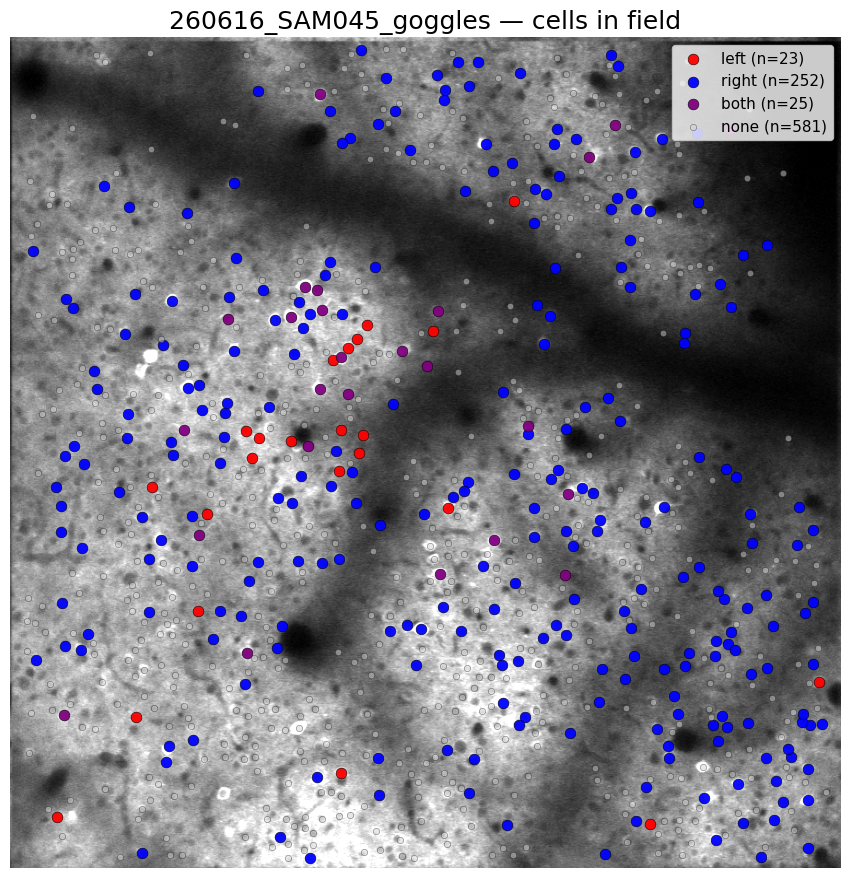

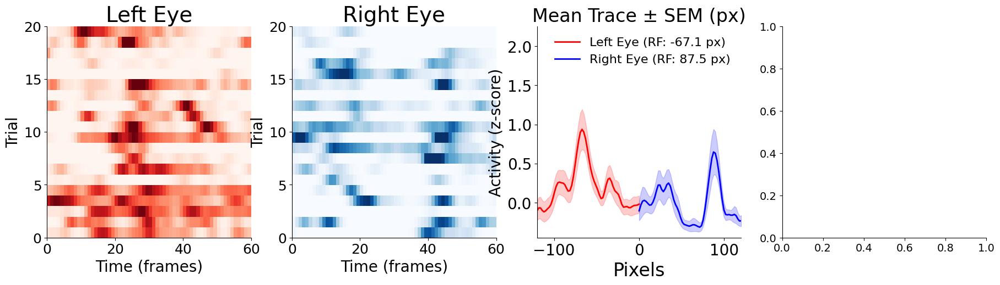

In [3]:
D = DisparityDevice(mouse_name="SAM045", record_date="260616",
                    experiment_name="goggles")
print("eyes:", D.present_eyes)                 # -> ['right', 'left']

# --- load cached stats if present, else compute once and save ---
pkl_path = os.path.join(D.data_dir, f"{D.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = SessionAnalyzer(D).analyze_session_stats(n_iterations=200)  # slow (1355 cells)
    SessionAnalyzer(D).save_dataframe(stats_df)                            # -> pkl_path
sv = SessionVisualizer(D, stats_df=stats_df)
sets = sv.print_summary()
sv.plot_summary()
sv.plot_location_map()

cv_monocular = CellVisualizer(D)
for cell in sorted(sets['left']):
    cv_monocular.make_comparison_plot(cell); plt.show()

Directory results already exists
Loaded cached stats: D:/data-distance-coding-project/processed-data\260713_SAM045_goggles-disparity\260713_SAM045_goggles-disparity_dataframe.pkl
 Session: 260713_SAM045_goggles-disparity
 Disparities (deg): [-20, -10, 0, 10, 20]
 Total cells: 1355
--------------------------------------------------
 Disparity -20° reliable   :  154  ( 11.4%)
 Disparity -10° reliable   :  203  ( 15.0%)
 Disparity +0° reliable    :  147  ( 10.8%)
 Disparity +10° reliable   :  186  ( 13.7%)
 Disparity +20° reliable   :  175  ( 12.9%)
--------------------------------------------------
 Any disparity             :  382  ( 28.2%)
 None                      :  973  ( 71.8%)
 Session: 260713_SAM045_goggles-disparity
 Disparities (deg): [-20, -10, 0, 10, 20]
 Total cells: 1355
--------------------------------------------------
 Disparity -20° reliable   :  154  ( 11.4%)
 Disparity -10° reliable   :  203  ( 15.0%)
 Disparity +0° reliable    :  147  ( 10.8%)
 Disparity +10° reliab

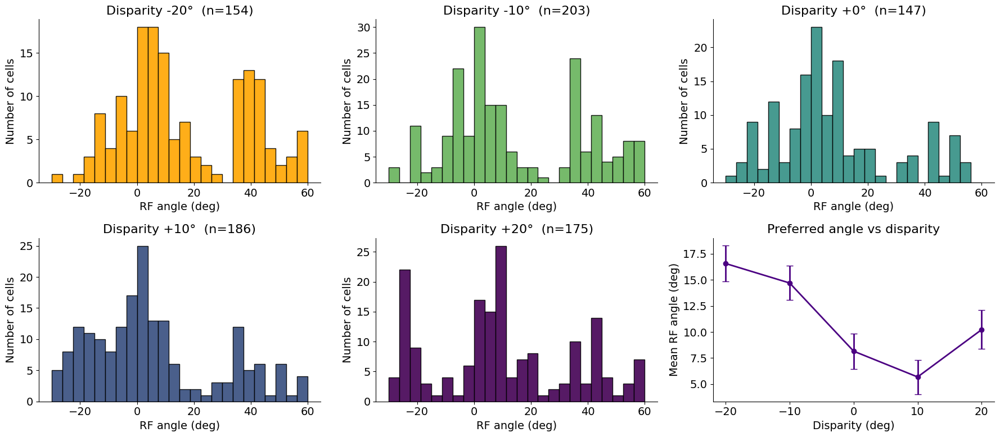

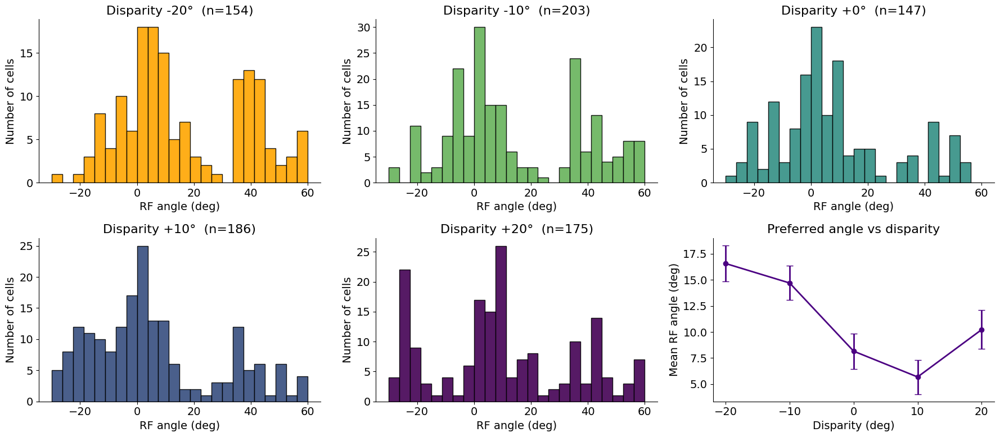

In [25]:
Dd = DisparityStimDevice(mouse_name="SAM045", record_date="260713",
                         experiment_name="goggles-disparity")

pkl_path = os.path.join(Dd.data_dir, f"{Dd.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = DisparitySessionAnalyzer(Dd).analyze_session_stats(n_iterations=200)
    DisparitySessionAnalyzer(Dd).save_dataframe(stats_df)

from src.viz.DisparitySessionVisualizer import DisparitySessionVisualizer
sv = DisparitySessionVisualizer(Dd, stats_df=stats_df)
sv.print_summary(); sv.plot_summary()

 Session: 260713_SAM045_goggles-disparity
 Disparities (deg): [-20, -10, 0, 10, 20]
 mean_corr floor: 0.9
 Total cells: 1355
--------------------------------------------------
 Disparity -20° reliable   :   15  (  1.1%)
 Disparity -10° reliable   :   35  (  2.6%)
 Disparity +0° reliable    :   18  (  1.3%)
 Disparity +10° reliable   :   29  (  2.1%)
 Disparity +20° reliable   :   21  (  1.5%)
--------------------------------------------------
 Any disparity             :   52  (  3.8%)
 None                      : 1303  ( 96.2%)
 Session: 260713_SAM045_goggles-disparity
 Disparities (deg): [-20, -10, 0, 10, 20]
 mean_corr floor: 0.9
 Total cells: 1355
--------------------------------------------------
 Disparity -20° reliable   :   15  (  1.1%)
 Disparity -10° reliable   :   35  (  2.6%)
 Disparity +0° reliable    :   18  (  1.3%)
 Disparity +10° reliable   :   29  (  2.1%)
 Disparity +20° reliable   :   21  (  1.5%)
--------------------------------------------------
 Any disparity    

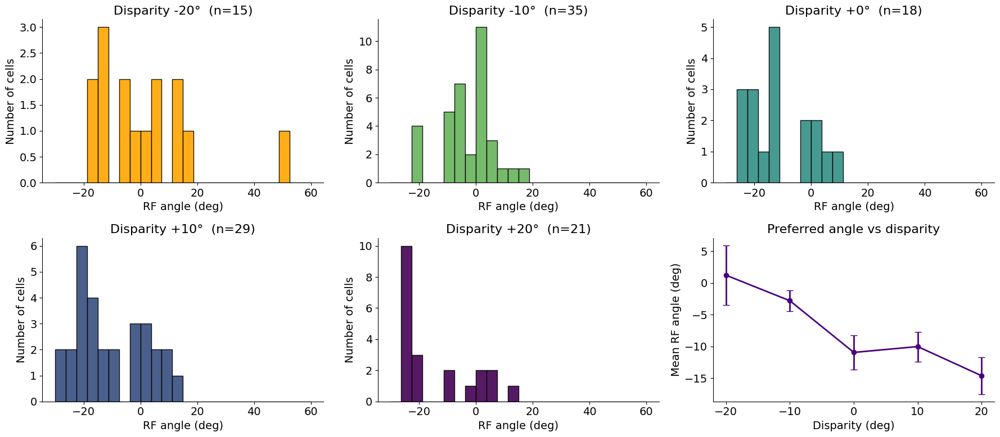

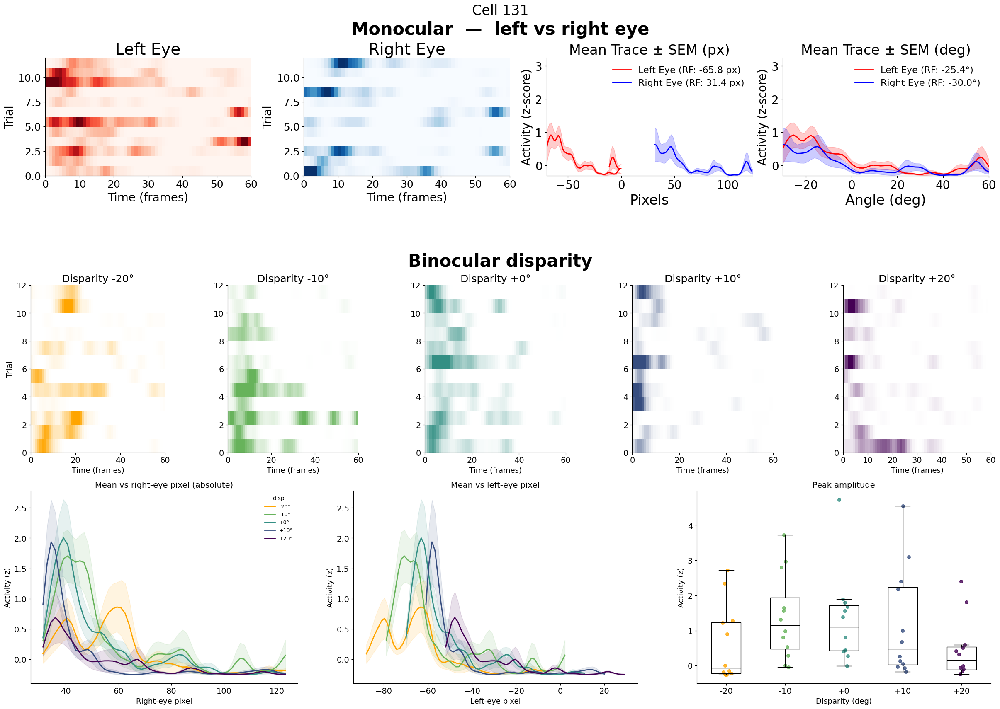

c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


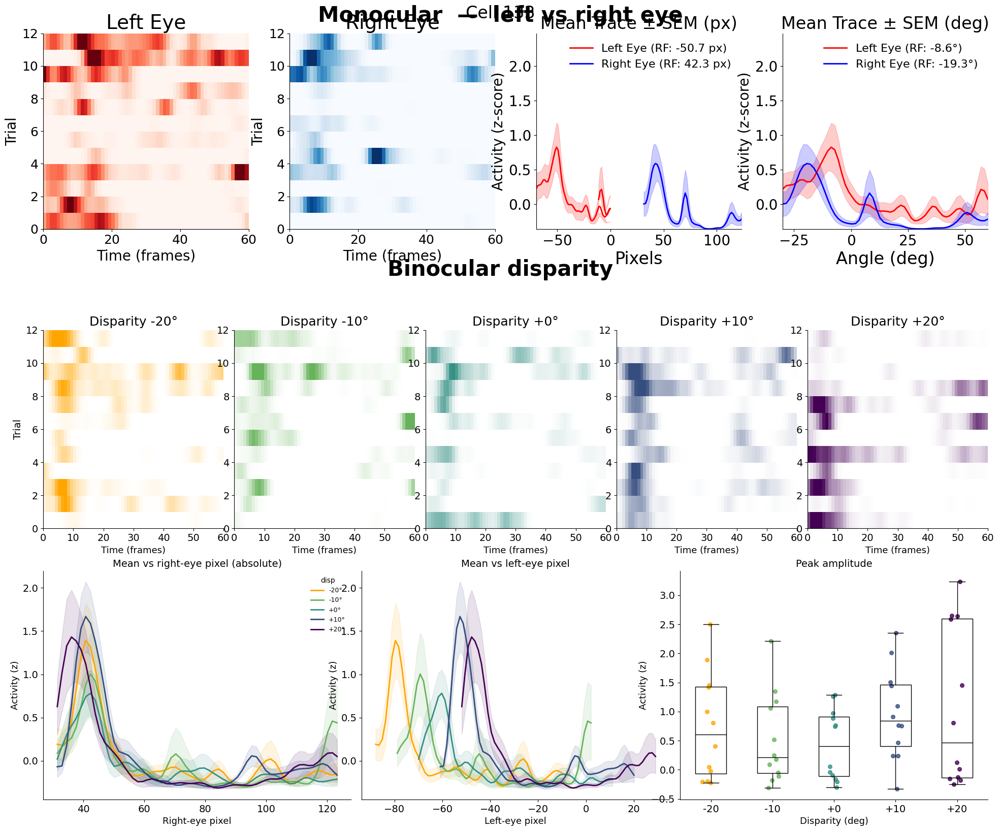

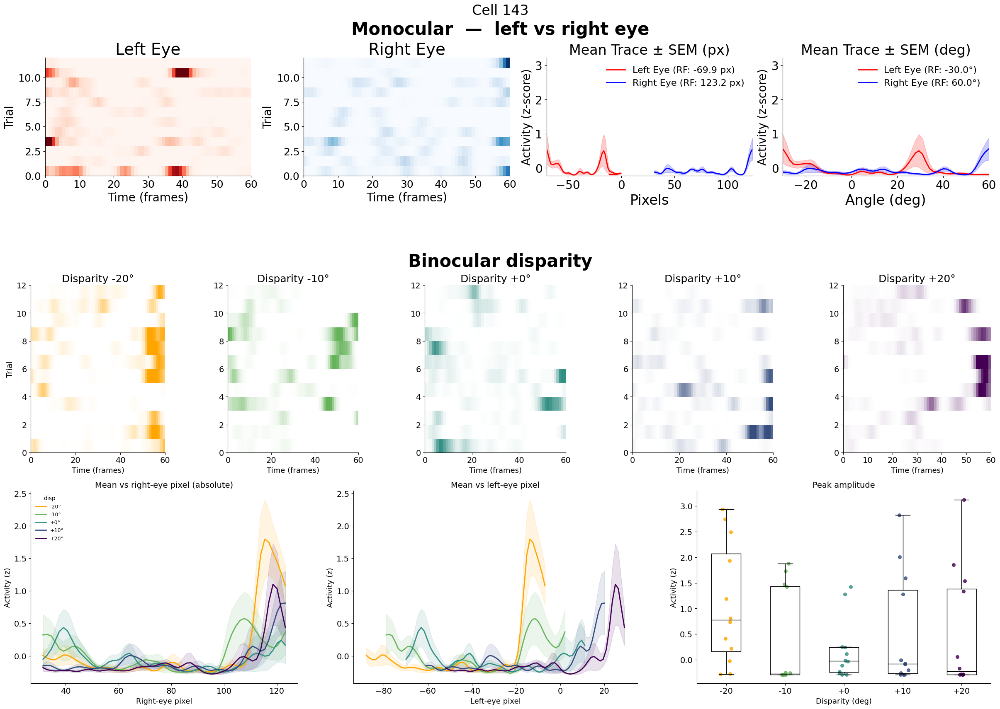

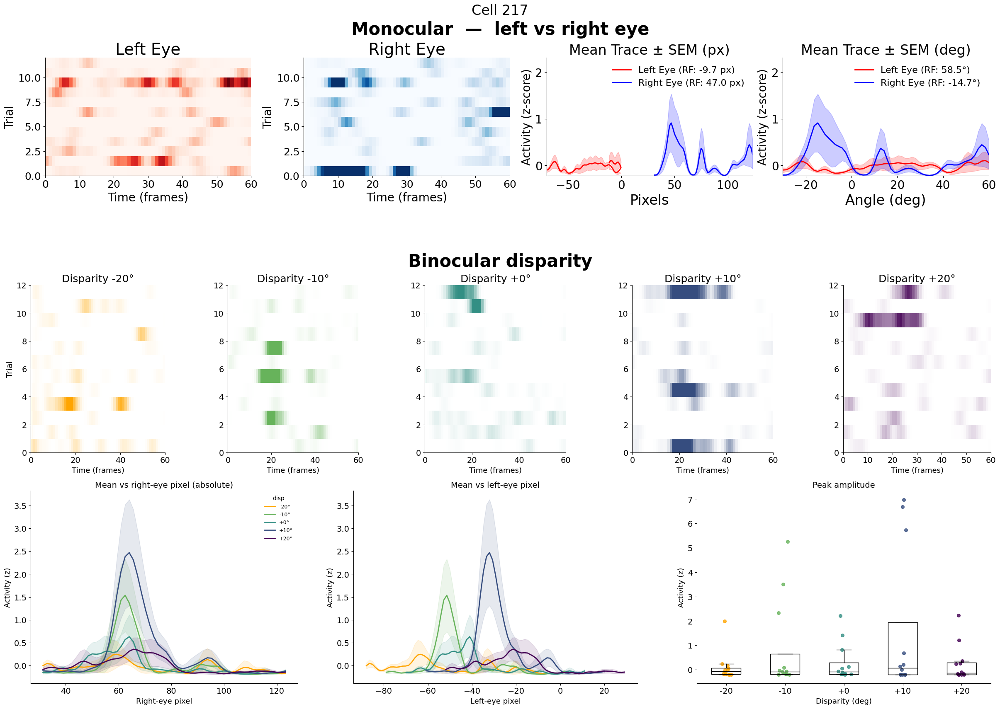

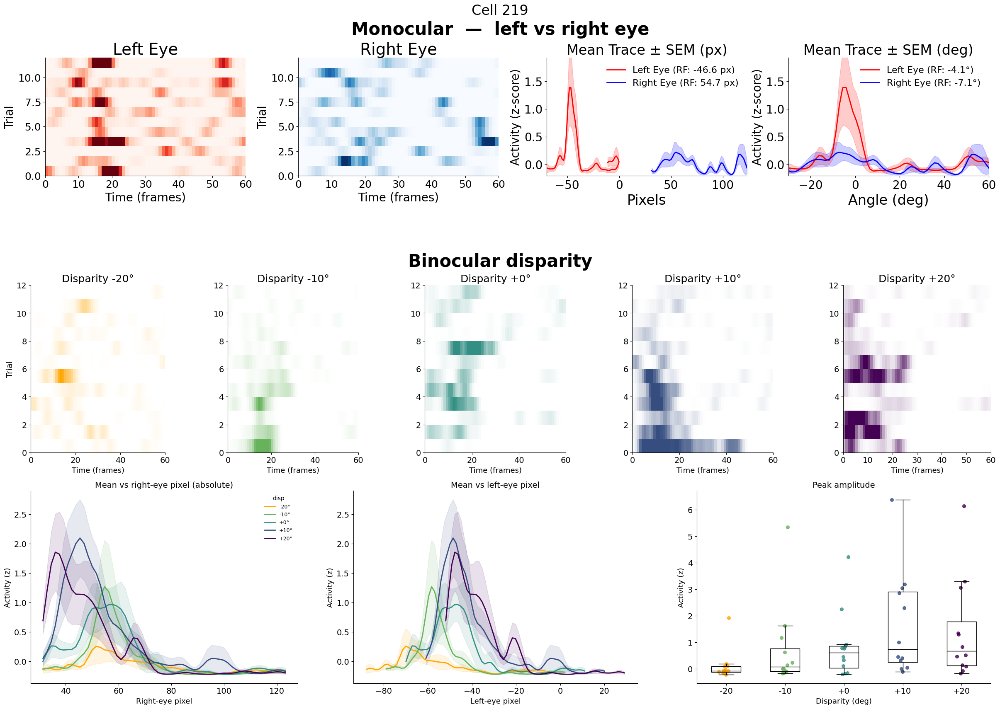

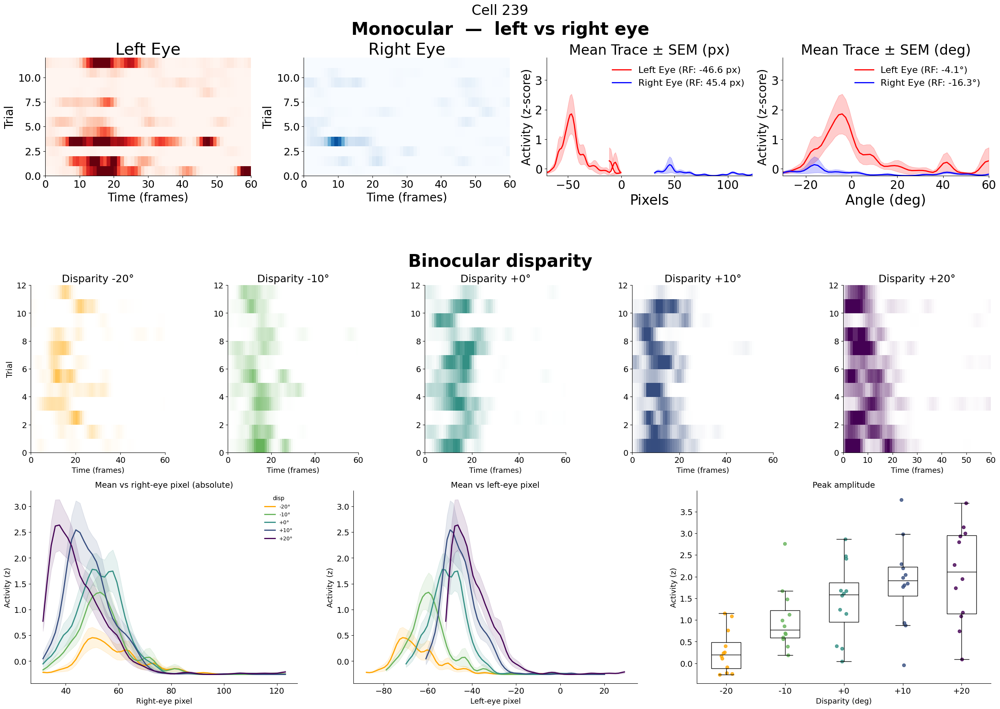

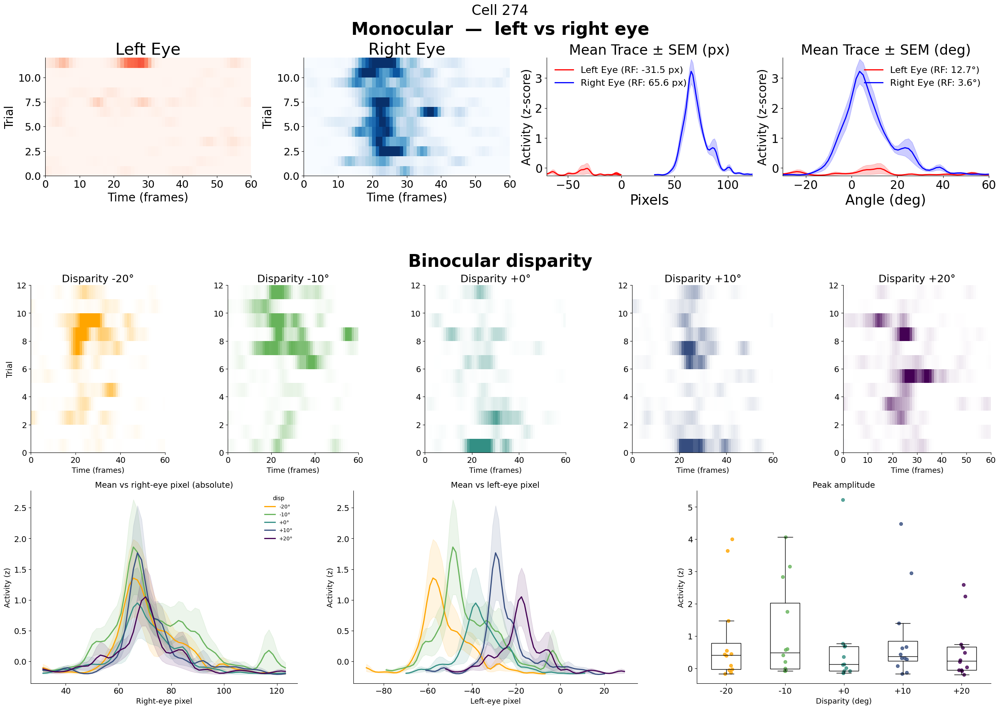

c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


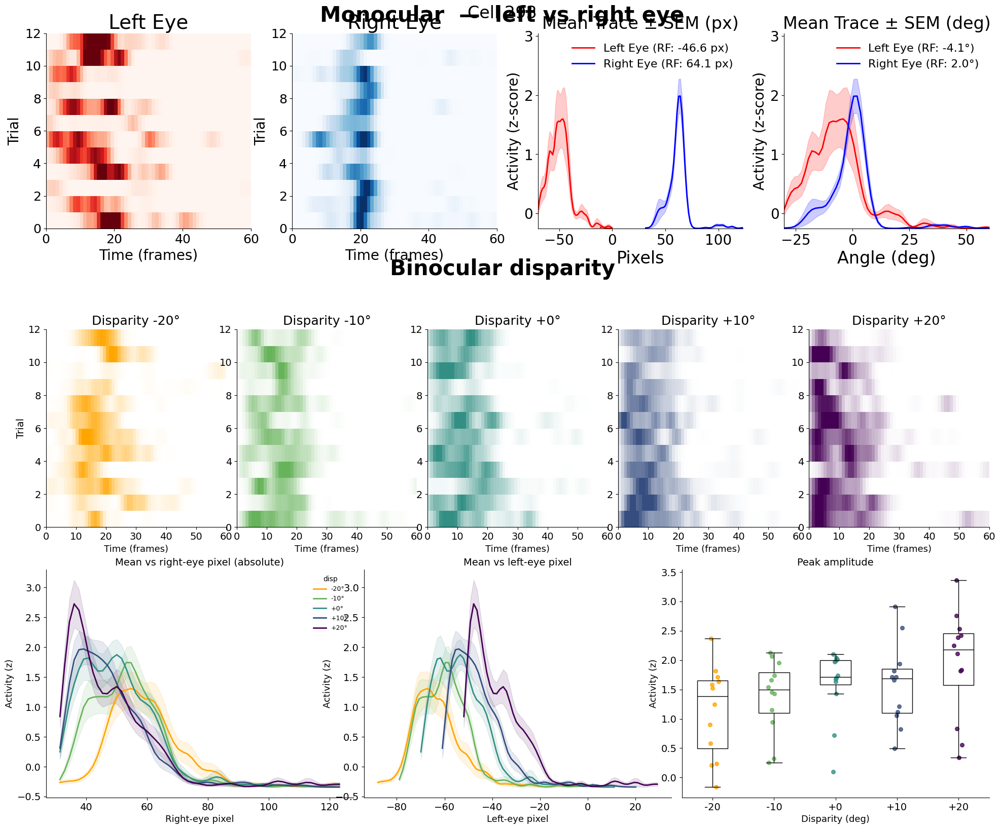

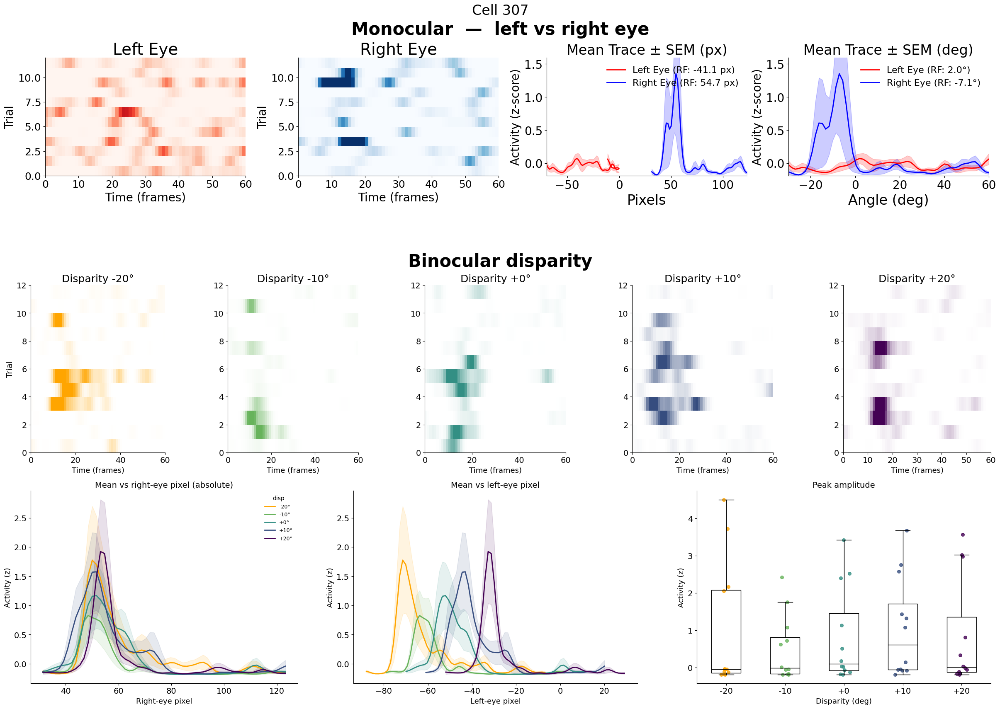

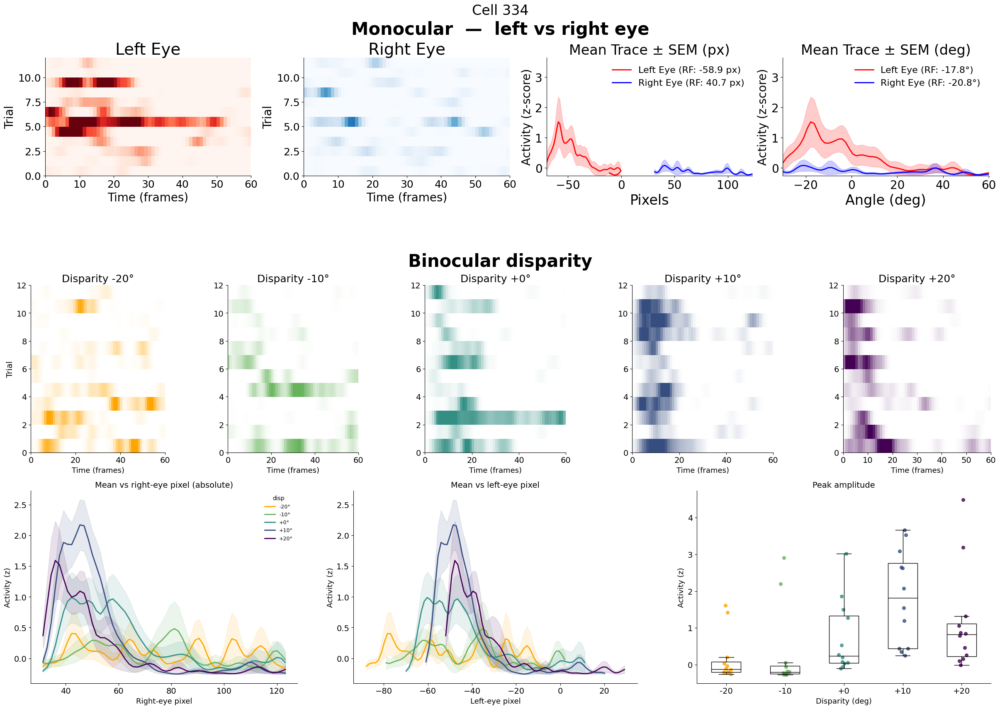

c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


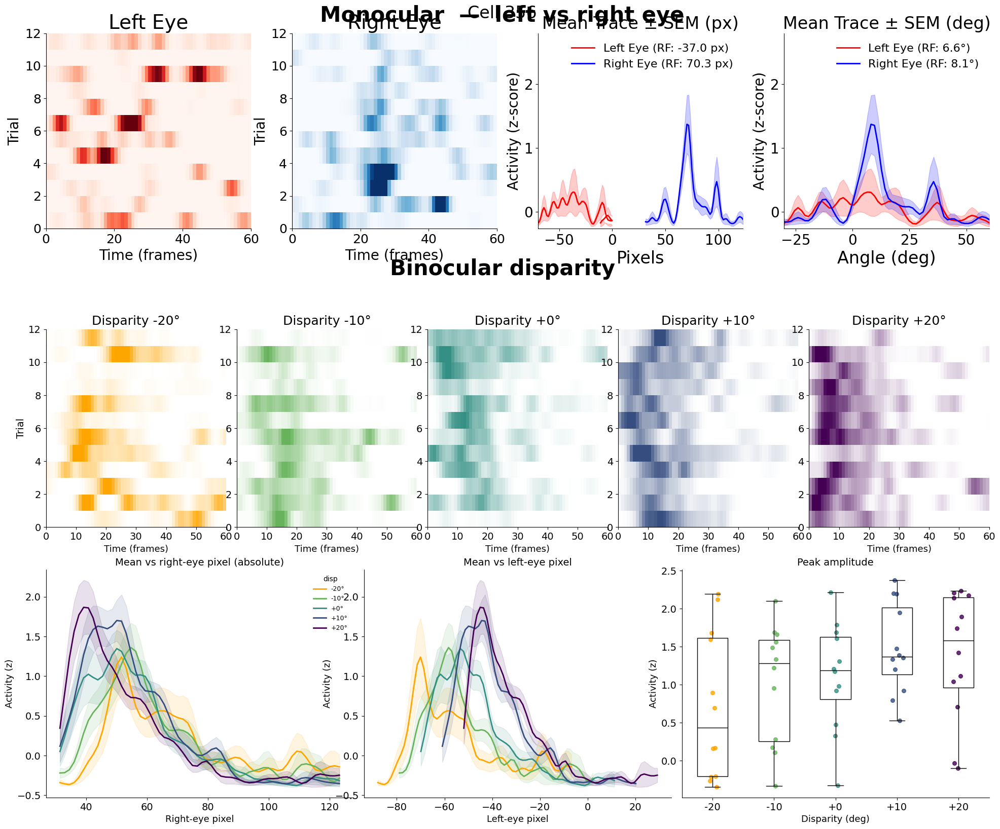

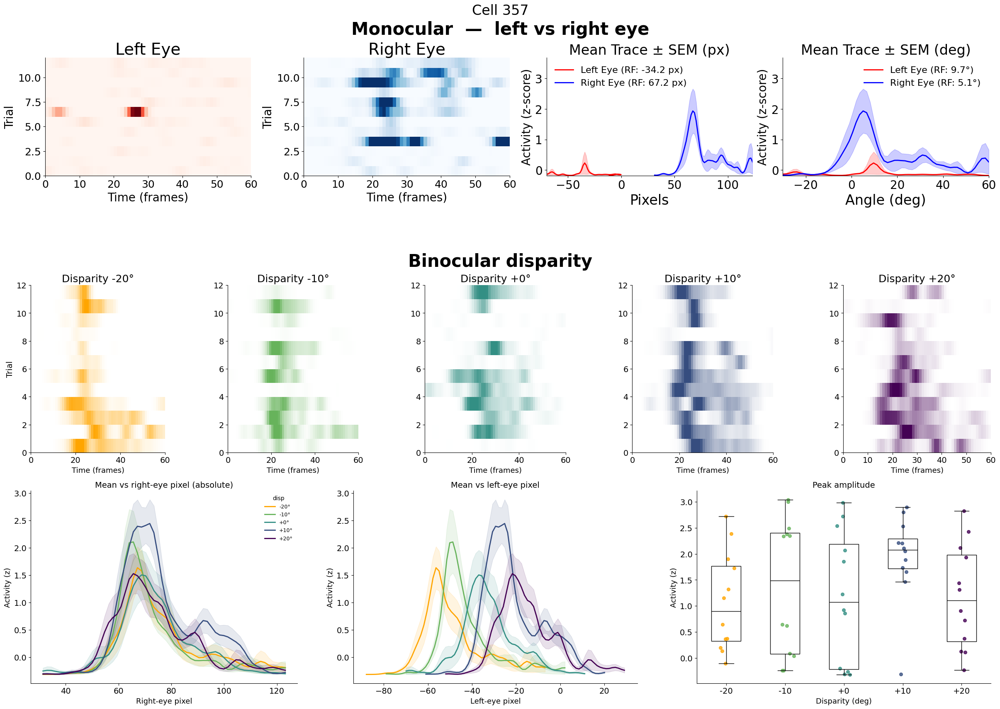

In [ ]:
import matplotlib.pyplot as plt
from src.viz.DisparityCellVisualizer import DisparityCellVisualizer

# sv already built with your cached stats_df (see the load/save cell), e.g.:
# sv = DisparitySessionVisualizer(Dd, stats_df=stats_df)

sv.reliable_sets(corr_threshold=0.9)          # sets gated by mean_corr >= 0.3
sv.print_summary(corr_threshold=0.9)          # counts reflect the floor
sv.plot_summary(corr_threshold=0.9)           # histograms reflect the floor


# and for the cell-plot loop from before:
reliable = sorted(sv.reliable_sets(corr_threshold=0.9)['any'])
for cell in reliable:
    cv.make_combined_plot(cell, units='px')
    plt.show()

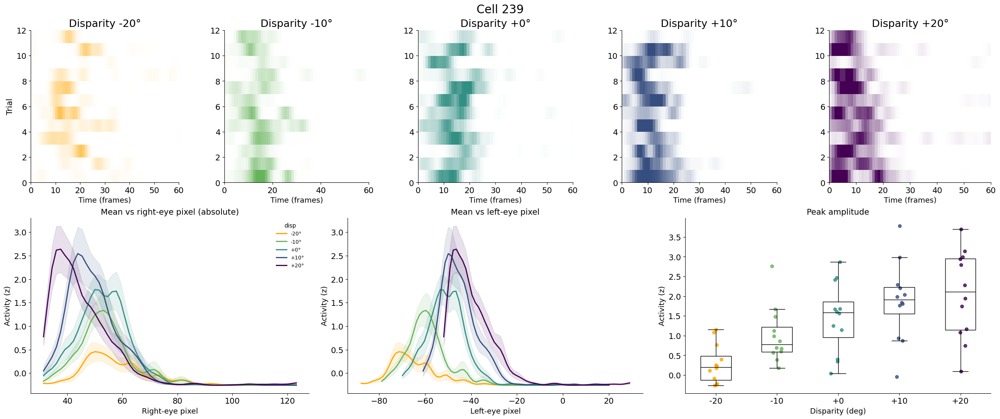

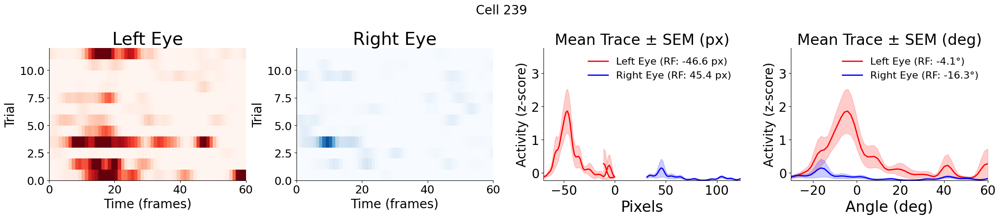

In [34]:
cv = DisparityCellVisualizer(Dd)
fig = cv.make_disparity_plot(239, units='px') 
fig = cv_monocular.make_comparison_plot(239)                # nominal (default)

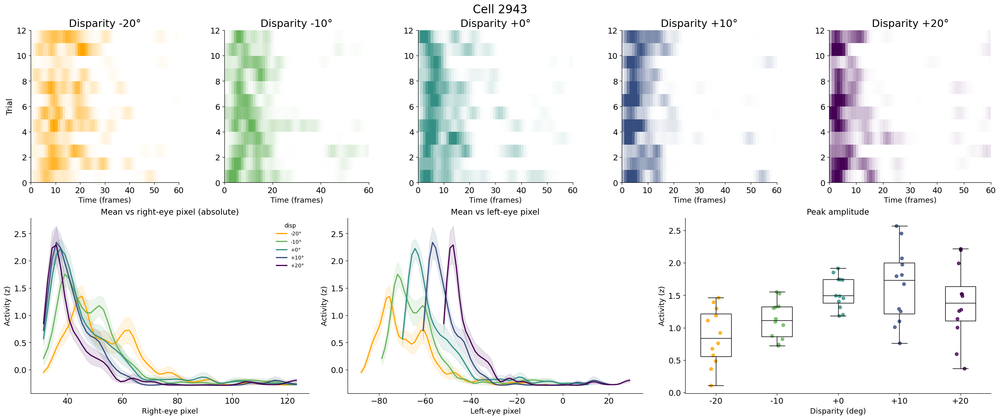

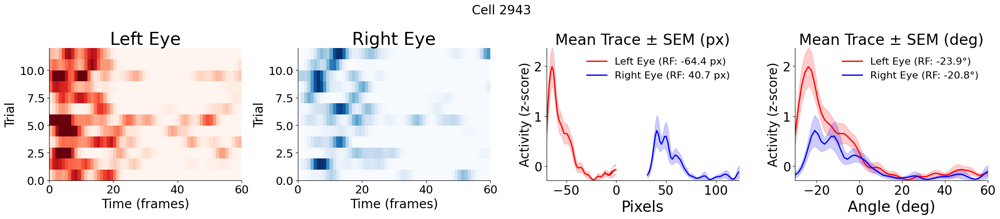

In [35]:
cv = DisparityCellVisualizer(Dd)
fig = cv.make_disparity_plot(2943, units='px') 
fig = cv_monocular.make_comparison_plot(2943)                

Directory results already exists
Directory results already exists


c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


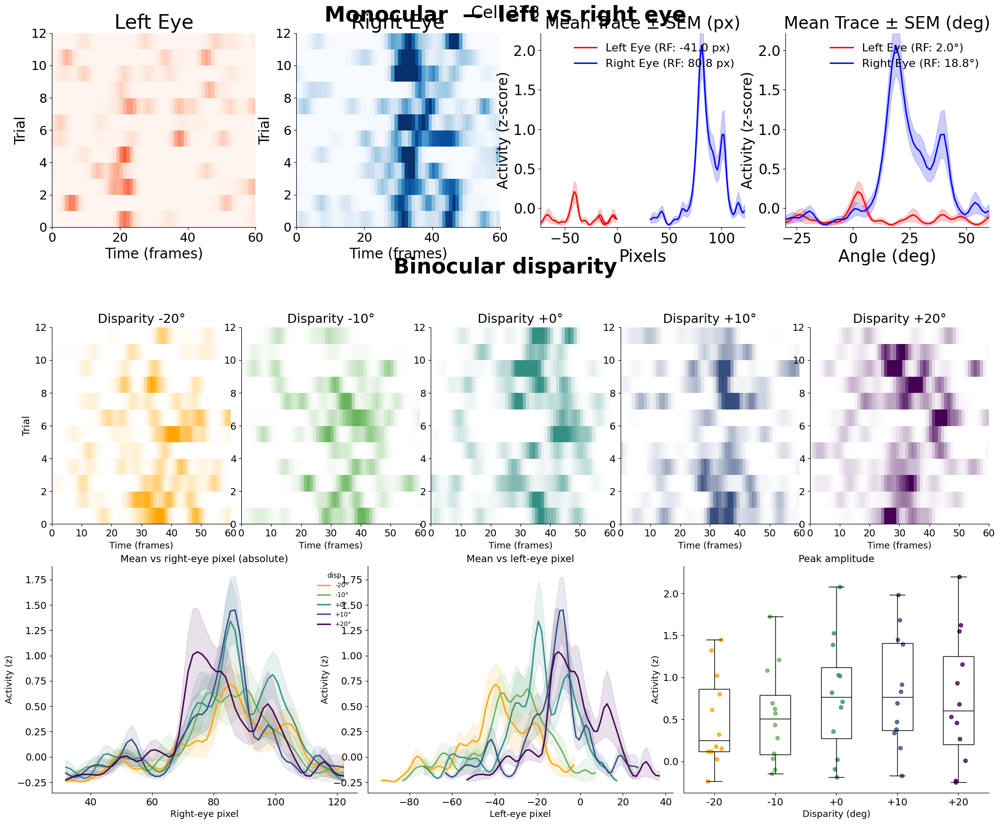

In [ ]:
from src.data.DisparityDevice import DisparityDevice
from src.data.DisparityStimDevice import DisparityStimDevice
from src.viz.CombinedCellVisualizer import CombinedCellVisualizer

M = DisparityDevice(mouse_name="SAM045", record_date="260715", experiment_name="goggles-monocular")
B = DisparityStimDevice(mouse_name="SAM045", record_date="260715", experiment_name="goggles-disparity")           # units='px' also forwarded to the disparity overlays

c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


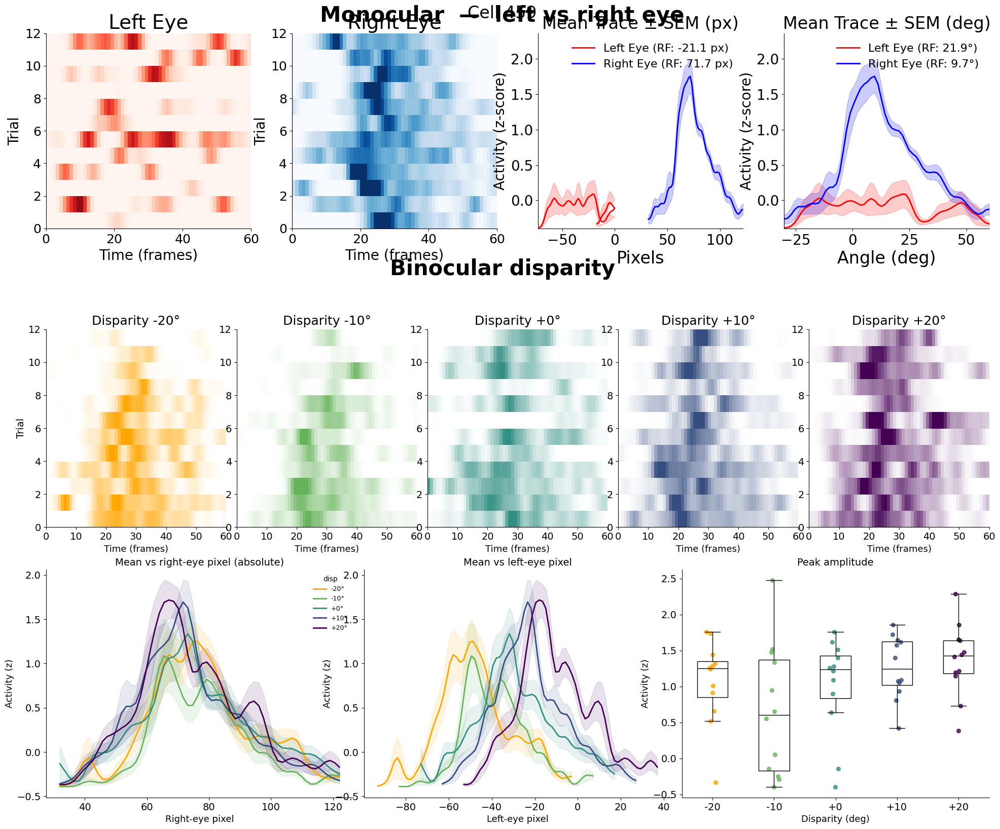

c:\Users\acostamendoza\AppData\Local\anaconda3\envs\distance-project\lib\site-packages\IPython\core\events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)


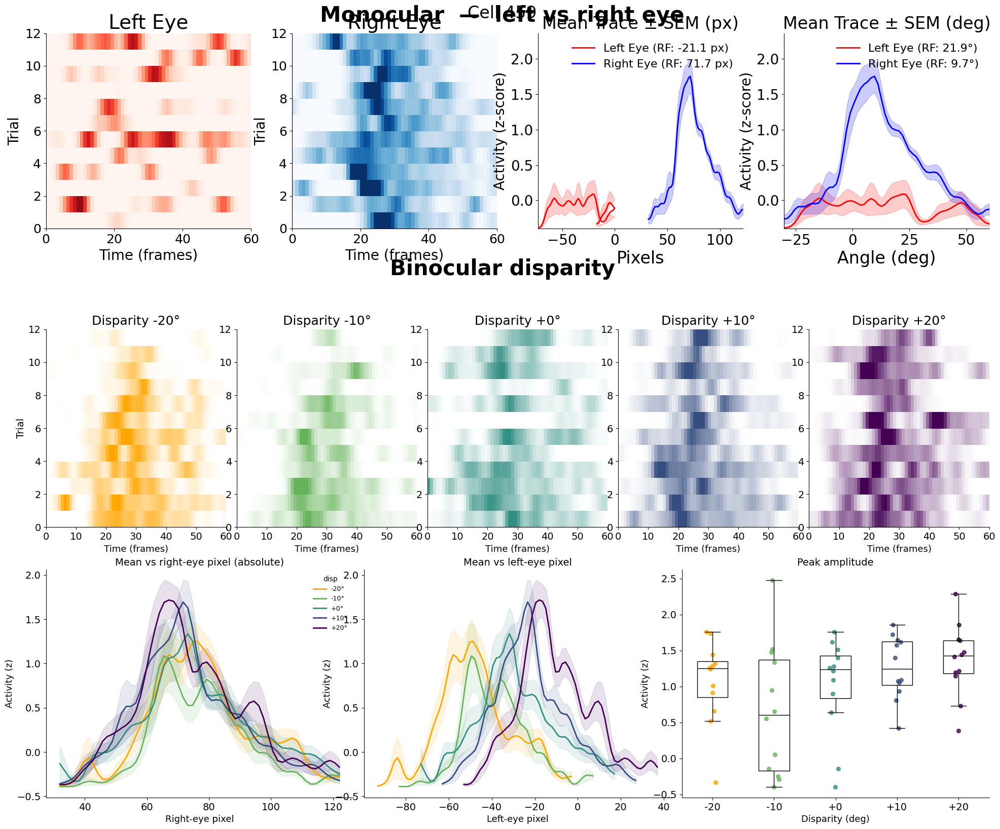

In [21]:
cv = CombinedCellVisualizer(M, B)
cv.make_combined_plot(459, units='px')   

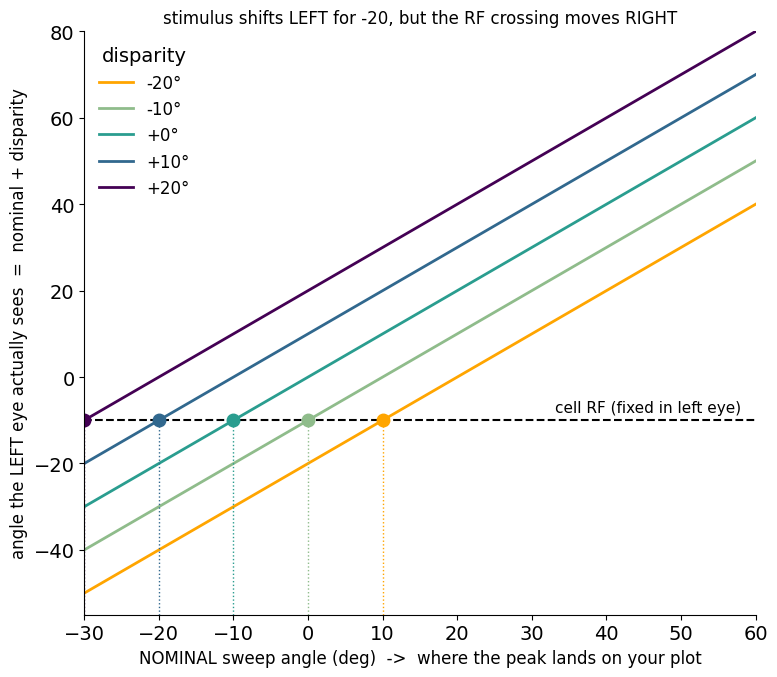

In [28]:
import numpy as np, matplotlib.pyplot as plt

nominal      = np.linspace(-30, 60, 100)
disparities  = [-20, -10, 0, 10, 20]
colors       = ['#FFA500', '#8FBC8B', '#2a9d8f', '#31688e', '#440154']
RF_left      = -10.0    # the cell's fixed RF in the LEFT eye (deg)

fig, ax = plt.subplots(figsize=(8, 7))
ax.axhline(RF_left, color='k', ls='--', lw=1.5)
ax.text(58, RF_left + 2, 'cell RF (fixed in left eye)', ha='right', fontsize=11)

for d, c in zip(disparities, colors):
    ax.plot(nominal, nominal + d, color=c, lw=2, label=f'{d:+d}°')  # left angle = nominal + disparity
    x_fire = RF_left - d                                            # nominal angle where it crosses the RF
    ax.plot(x_fire, RF_left, 'o', color=c, ms=9)
    ax.plot([x_fire, x_fire], [-55, RF_left], color=c, ls=':', lw=1)

ax.set_xlabel('NOMINAL sweep angle (deg)  ->  where the peak lands on your plot', fontsize=12)
ax.set_ylabel('angle the LEFT eye actually sees  =  nominal + disparity', fontsize=12)
ax.set_title('stimulus shifts LEFT for -20, but the RF crossing moves RIGHT', fontsize=12)
ax.legend(title='disparity', frameon=False)
ax.set_xlim(-30, 60); ax.set_ylim(-55, 80)
plt.tight_layout()
plt.show()


AttributeError: 'DisparityStimDevice' object has no attribute 'left_fit'

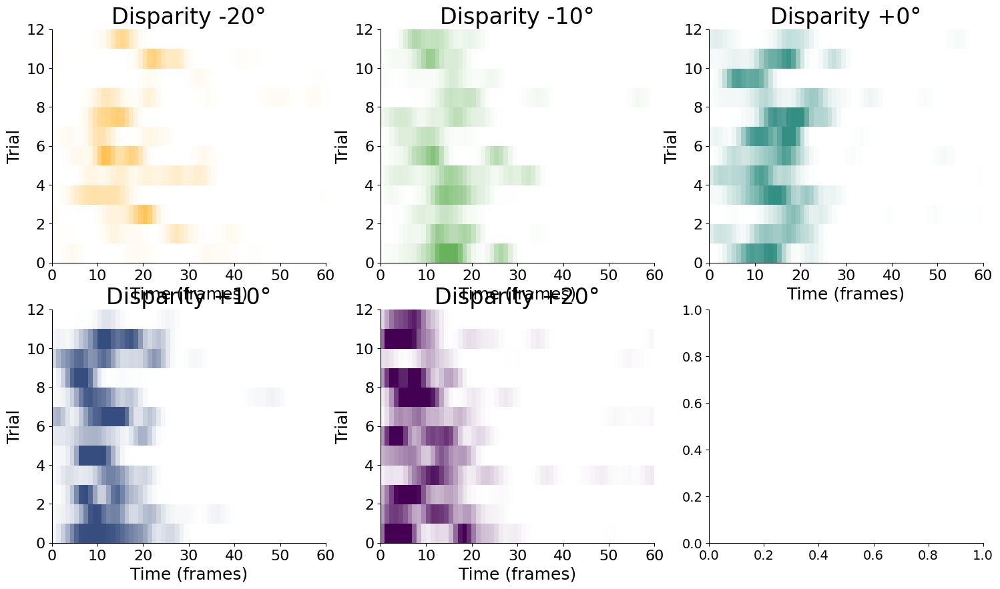

In [24]:
cv = DisparityCellVisualizer(Dd)
fig = cv.make_disparity_plot(239)                 # nominal (default)
fig = cv.make_disparity_plot(239, x_axis='left_px')  # disparity-corrected (left-eye angle)